In [1]:
!pip install deep_sort_realtime gdown

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 37.6 MB/s eta 0:00:00


Downloading...
From: https://drive.google.com/uc?id=1nAQAFmaoXxB8rJ21uHIw_KAz7NYB7pn6
To: /content/downloaded_video.mp4
100%|██████████| 3.74M/3.74M [00:00<00:00, 51.4MB/s]
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


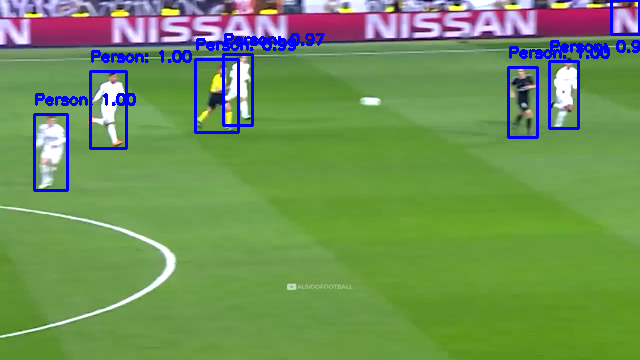

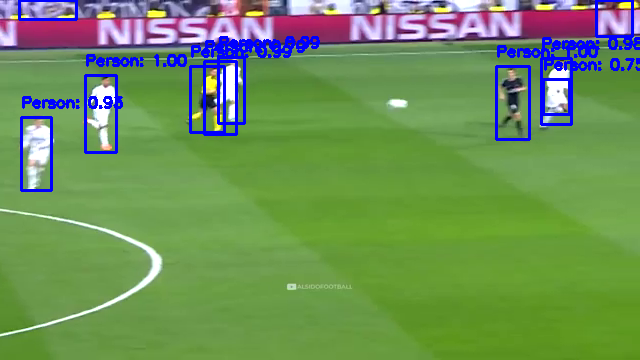

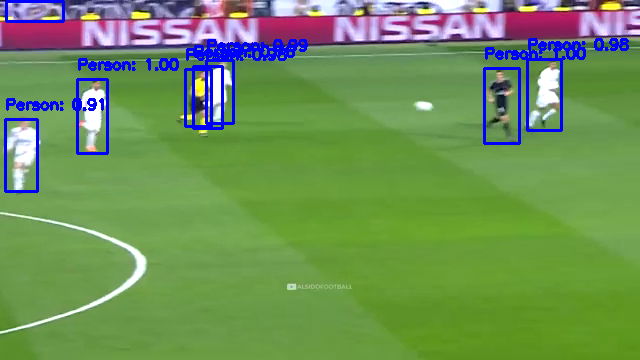

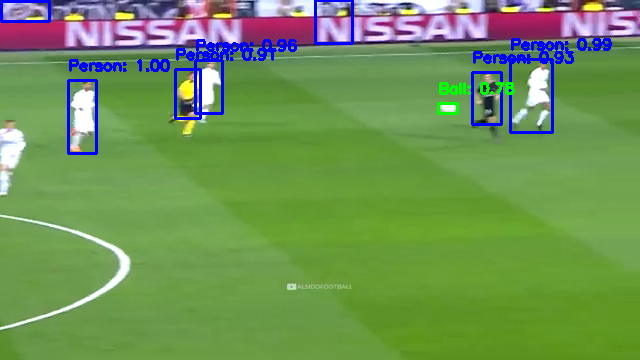

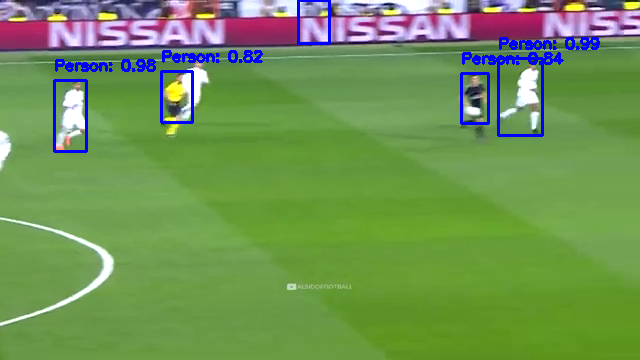

...

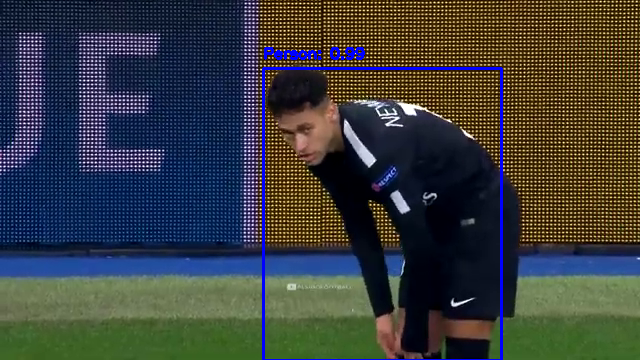

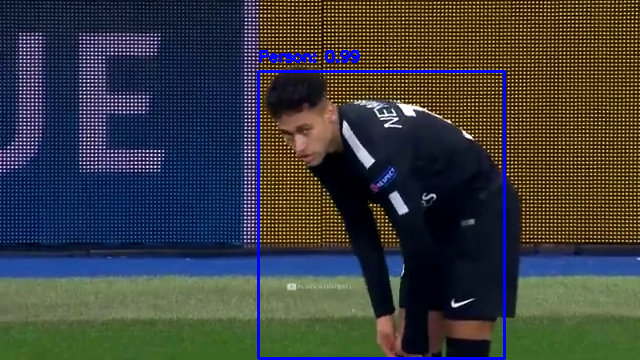

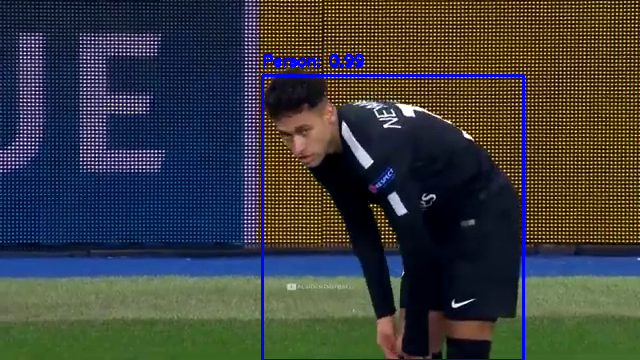

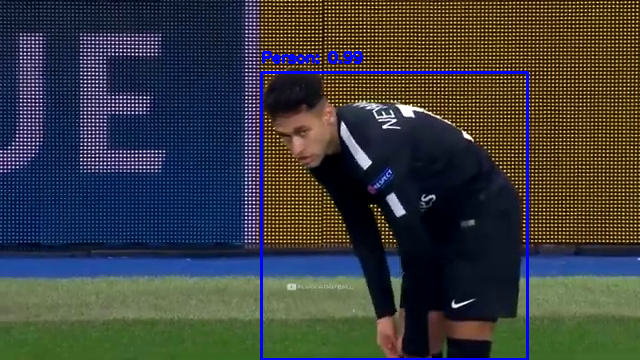

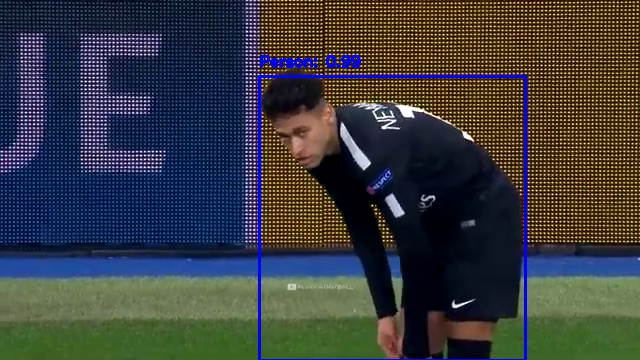

In [ ]:
import gdown
from torchvision.transforms import functional as F
import cv2
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from google.colab.patches import cv2_imshow  # For displaying images in Colab

# Download the video using gdown (replace with your Google Drive URL)
video_url = 'https://drive.google.com/uc?id=1nAQAFmaoXxB8rJ21uHIw_KAz7NYB7pn6'
video_path = 'downloaded_video.mp4'

# Download video from Google Drive
gdown.download(video_url, video_path, quiet=False)

# Load the model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = fasterrcnn_resnet50_fpn(pretrained=True).to(device).eval()

# Define a function to detect objects in a single frame
def detect_objects(frame, model):
    # Convert frame to tensor and normalize it for the model
    frame_tensor = F.to_tensor(frame).to(device)
    detections = model([frame_tensor])[0]

    # Define thresholds and class mappings
    threshold = 0.7
    detected_objects = []

    for i in range(len(detections['boxes'])):
        score = detections['scores'][i].item()
        if score > threshold:
            box = detections['boxes'][i].detach().cpu().numpy()
            label = detections['labels'][i].item()
            detected_objects.append((box, label, score))

    return detected_objects

# Open video for processing
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print("Error: Could not open video.")
    exit()

frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = int(cap.get(cv2.CAP_PROP_FPS))
output_path = 'tracked_output_task1_fixed.mp4'  # Output file path on local machine

# Define VideoWriter to save the output video
fourcc = cv2.VideoWriter_fourcc(*'mp4v')  # Codec for MP4
out = cv2.VideoWriter(output_path, fourcc, fps, (frame_width, frame_height))

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    # Detect objects in the frame
    detected_objects = detect_objects(frame, model)

    # Draw bounding boxes and labels on the frame
    for box, label, score in detected_objects:
        if label in [1, 37]:  # 1 = Person, 37 = Sports Ball (COCO class IDs)
            x1, y1, x2, y2 = map(int, box)
            color = (255, 0, 0) if label == 1 else (0, 255, 0)  # Blue for person, Green for ball
            label_name = "Person" if label == 1 else "Ball"
            cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)  # Draw box
            cv2.putText(frame, f"{label_name}: {score:.2f}", (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

    # Write the processed frame to the output video
    out.write(frame)

    # Display the frame using cv2_imshow (for Colab)
    cv2_imshow(frame)

# Release resources
cap.release()
out.release()  # Ensure the output video is properly saved

print(f"Video saved to {output_path}")
